# TARANG: Waveguides

In [1]:
# ---- Importing Media --- #
from media import get_medium

SiN = get_medium(
    "si3n4",
    (0.600, 1.200),
)

SiO2 = get_medium(
    "sio2",
    (0.600, 1.200)
)

## Waveguide: Geometries

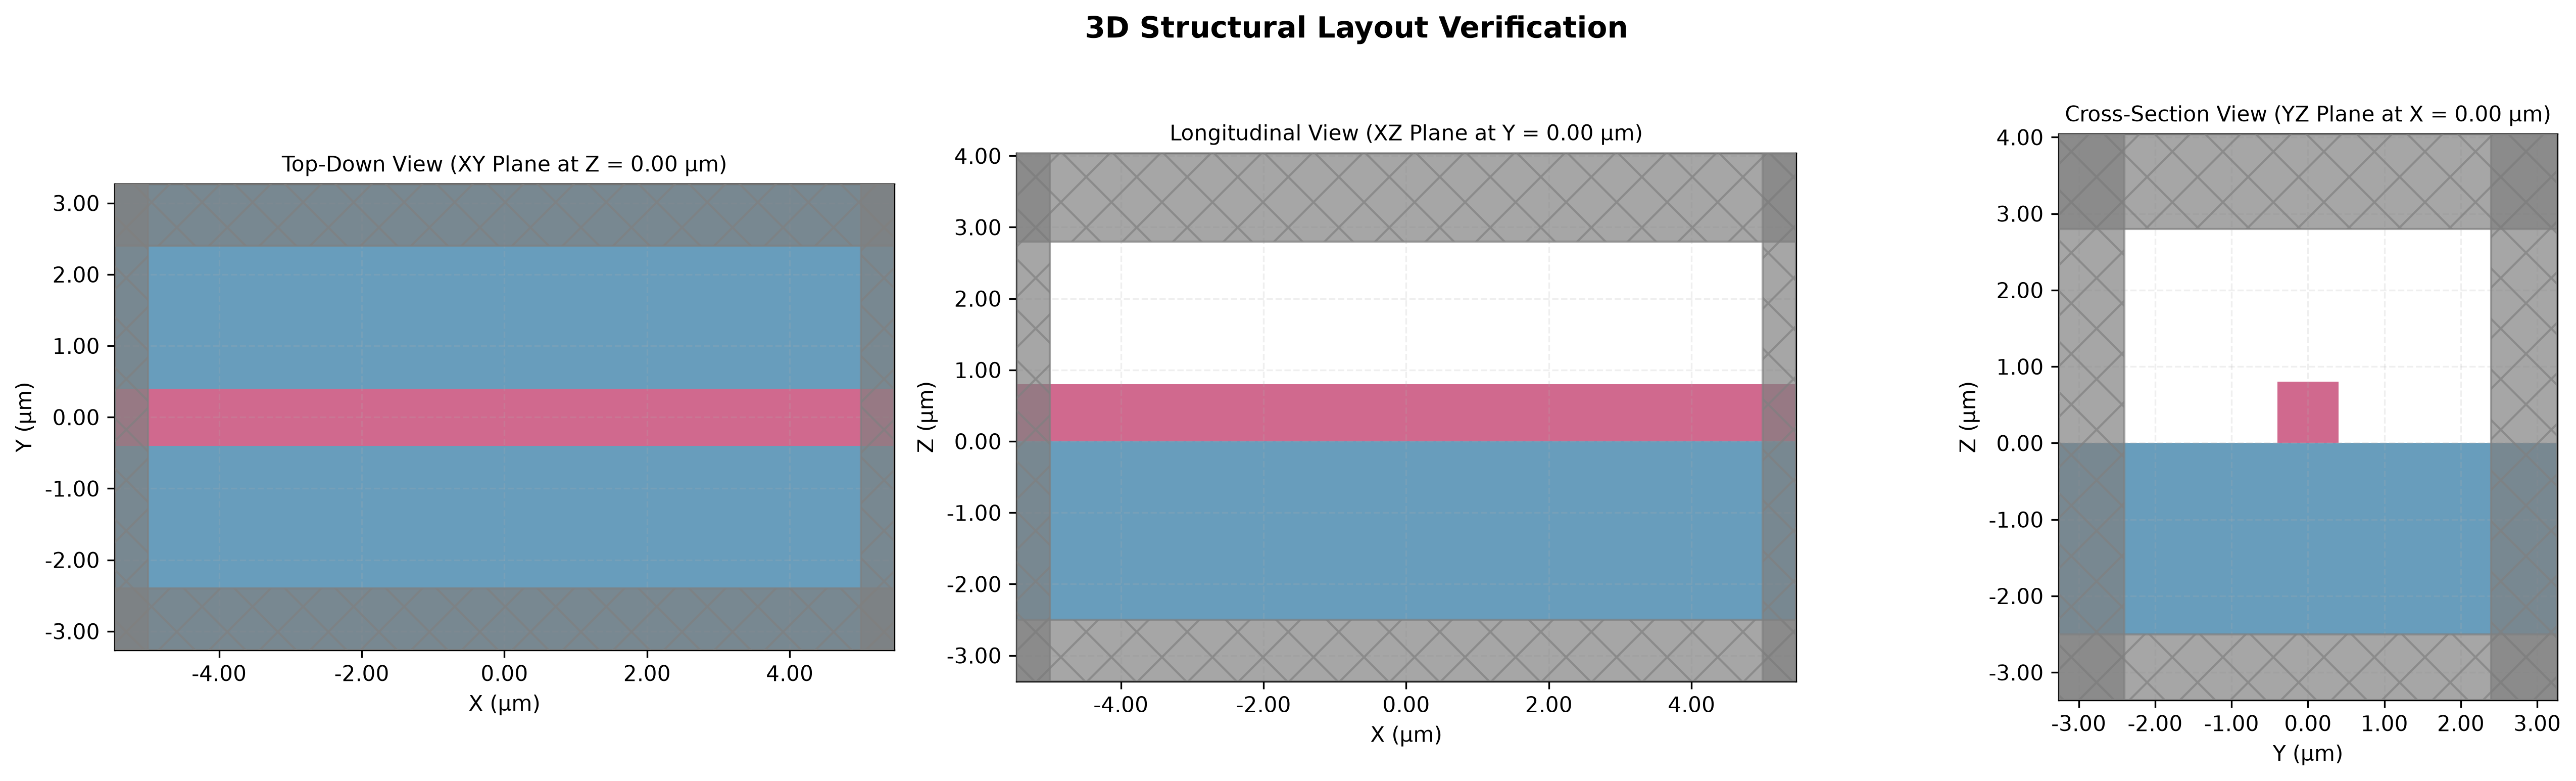

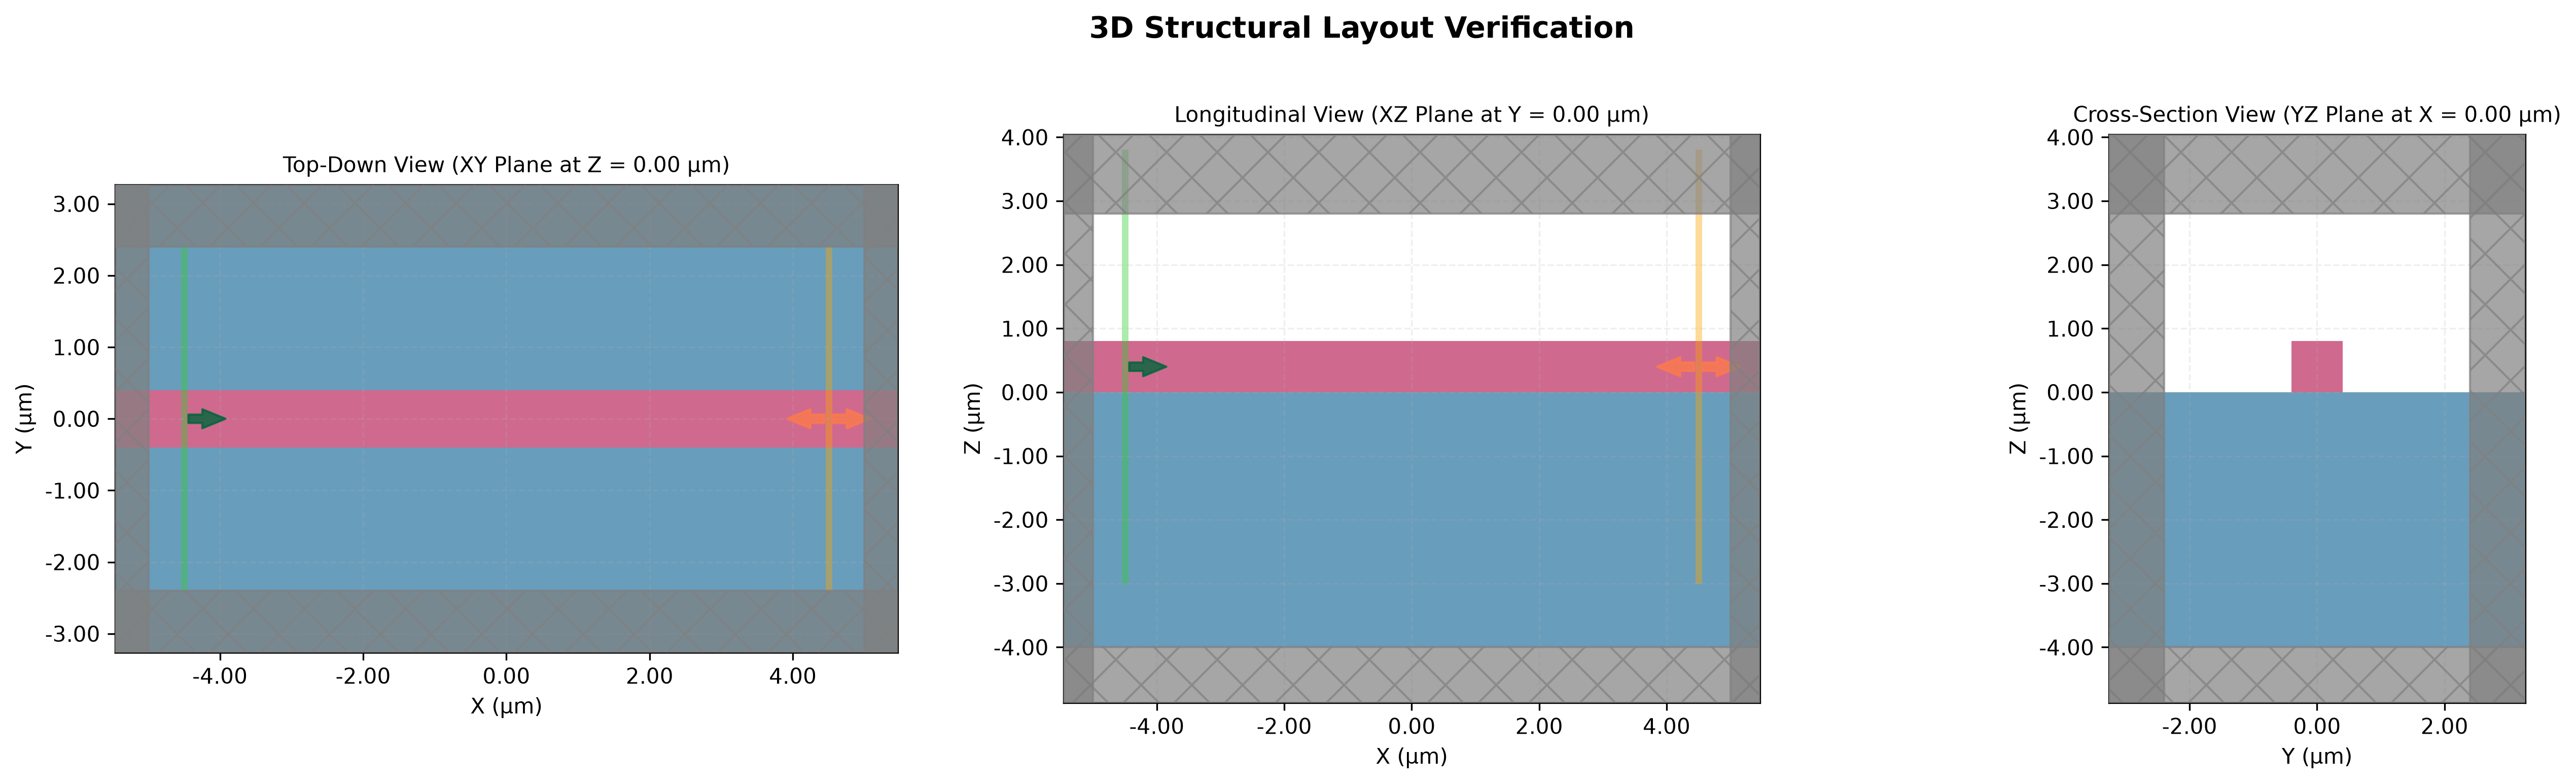

In [2]:
# ---- Waveguide Geometry Tests ---- #
from geometries import ridge_waveguide
from utilities import sim_plotter

from pathlib import Path 

example_passive_waveguide = ridge_waveguide.get_passive_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,
    
    box_height = 2.5,
    
    core_medium=SiN,
    box_medium=SiO2,
)

# The active ridge waveguide features a mode source and a mode monitor
# which the passive simulation otherwise lacks.
example_active_waveguide = ridge_waveguide.get_active_simulation(
    width=0.800,
    height=0.800,
    length=10.0,

    wavelength_um= 1.550,

    box_height = 4.0,
    
    core_medium=SiN,
    box_medium=SiO2,
)

# ---- Plotting to Verify Geometry ---- #
sim_plotter.display_3d(example_passive_waveguide, output_path = Path("example_passive_waveguide"), show = True)
sim_plotter.display_3d(example_active_waveguide, output_path = Path("example_active_waveguide"), show = True)

## Waveguide: Analysis

In [4]:
# ---- Analysis of a Defined Geometry ---- #
from geometries import ridge_waveguide
from pprint import pprint

waveguide_1550 = ridge_waveguide.get_passive_simulation(
    width = 0.800,
    height = 0.800,

    length = 2.0,

    core_medium = SiN,
    box_medium = SiO2,
    box_height = 4.0,

    wavelength_um = 1.550
)

print("----- Mode Analysis -----")
pprint(waveguide_1550.get_modes())
print("----- -----\n\n")

----- Mode Analysis -----
{'height_um': 0.8,
 'modes': [{'is_guided': True,
            'mode_index': 0,
            'neff': 1.6718693881067996,
            'polarization': 'TM',
            'te_fraction': 0.007588112496736447},
           {'is_guided': True,
            'mode_index': 1,
            'neff': 1.6516274548917378,
            'polarization': 'TE',
            'te_fraction': 0.9871554957075623},
           {'is_guided': False,
            'mode_index': 2,
            'neff': 1.370257443274624,
            'polarization': 'TM',
            'te_fraction': 0.024074352211609754},
           {'is_guided': False,
            'mode_index': 3,
            'neff': 1.3286001671369823,
            'polarization': 'TE',
            'te_fraction': 0.8521258324541608},
           {'is_guided': False,
            'mode_index': 4,
            'neff': 1.2861114725850076,
            'polarization': 'TM',
            'te_fraction': 0.07088067379992471},
           {'is_guided': False,
      

In [5]:
print("----- Confinement Analysis -----")
pprint(waveguide_1550.get_confinement())
print("----- -----\n\n")

----- Confinement Analysis -----
{'confinement_factor': 0.7384800768514407,
 'confinement_percent': 73.84800768514407,
 'effective_mode_area_um2': 2.869068132013928,
 'eval_domain_um2': 32.64,
 'physical_core_area_um2': 0.6400000000000001}
----- -----




In [6]:
print("----- Dispersion Analysis -----")
pprint(waveguide_1550.get_dispersion())
print("----- -----\n\n")

----- Dispersion Analysis -----
{'dispersion_ps_nm_km': 382.8095816901263,
 'dispersion_regime': 'Anomalous Dispersion (D > 0)',
 'is_singlemode': True,
 'neff_fundamental': 1.6516635106438564,
 'wavelength_um': 1.55}
----- -----




## Waveguide: Sweep Analysis

### Mode Sweep

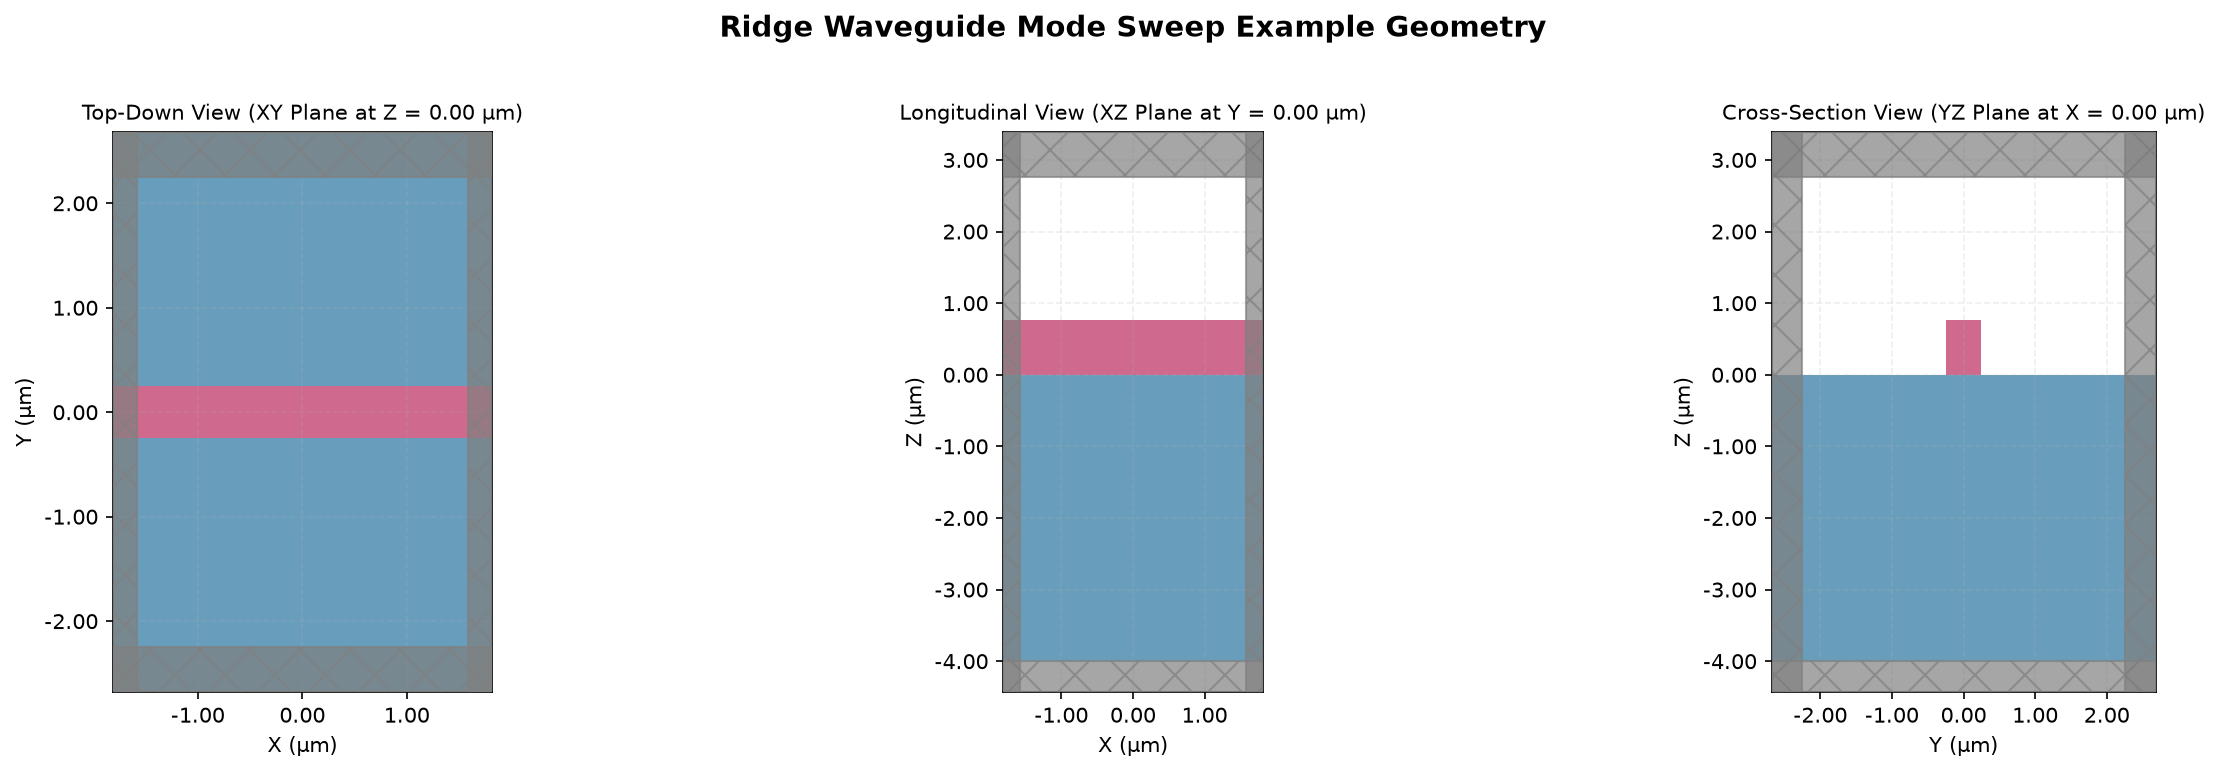

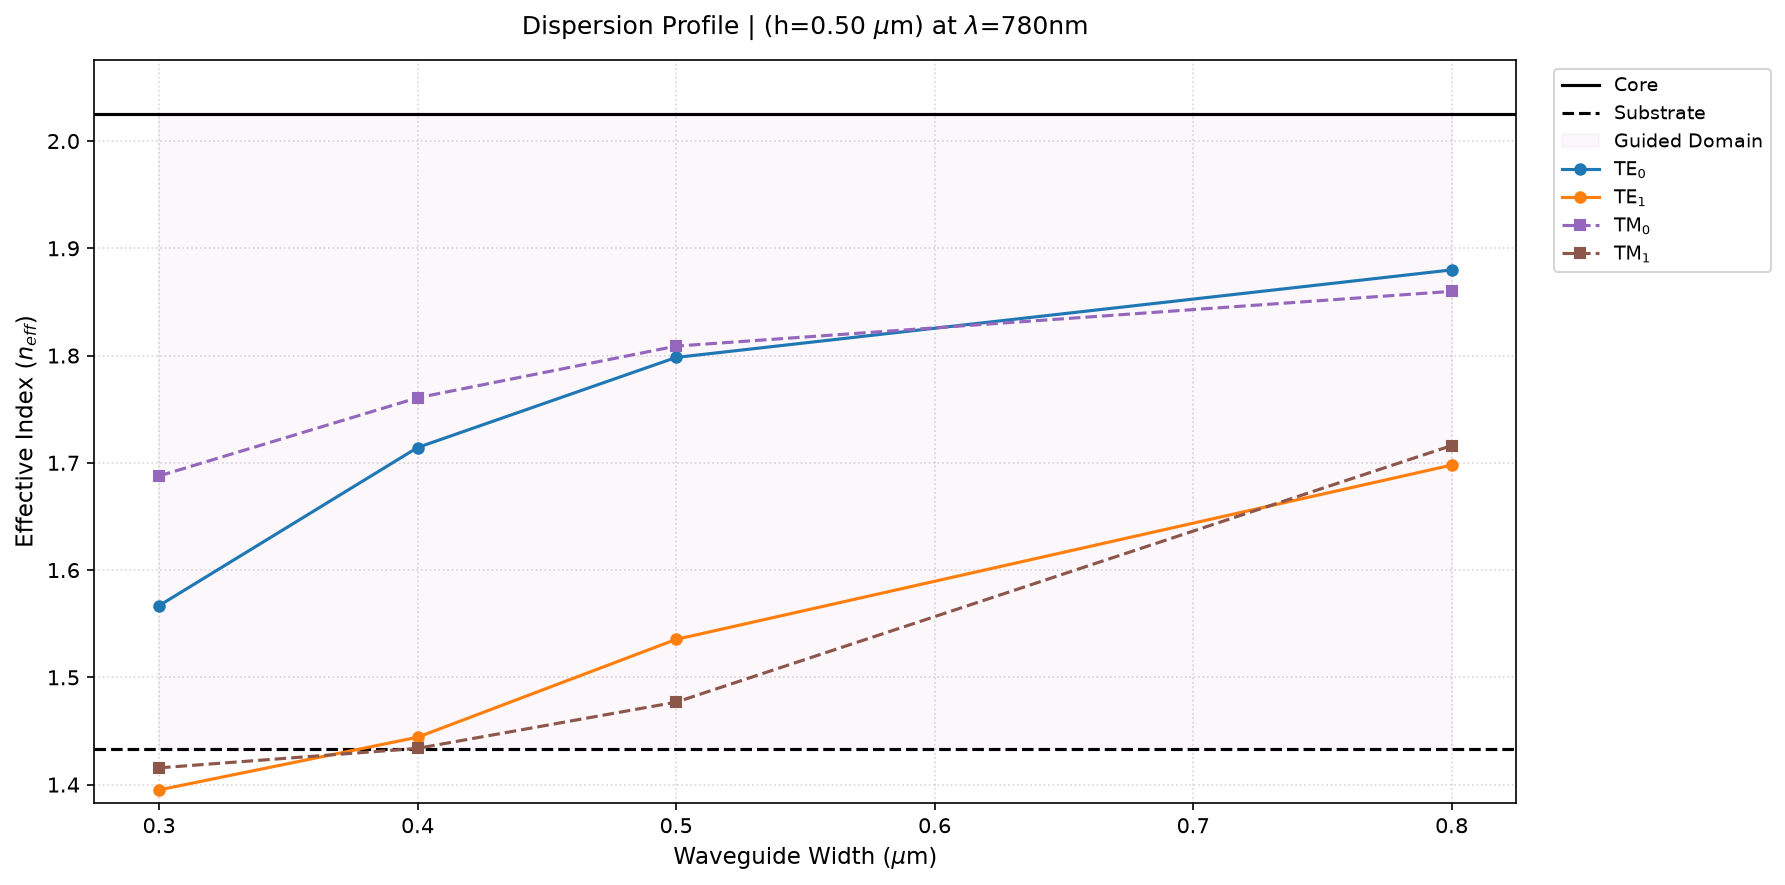

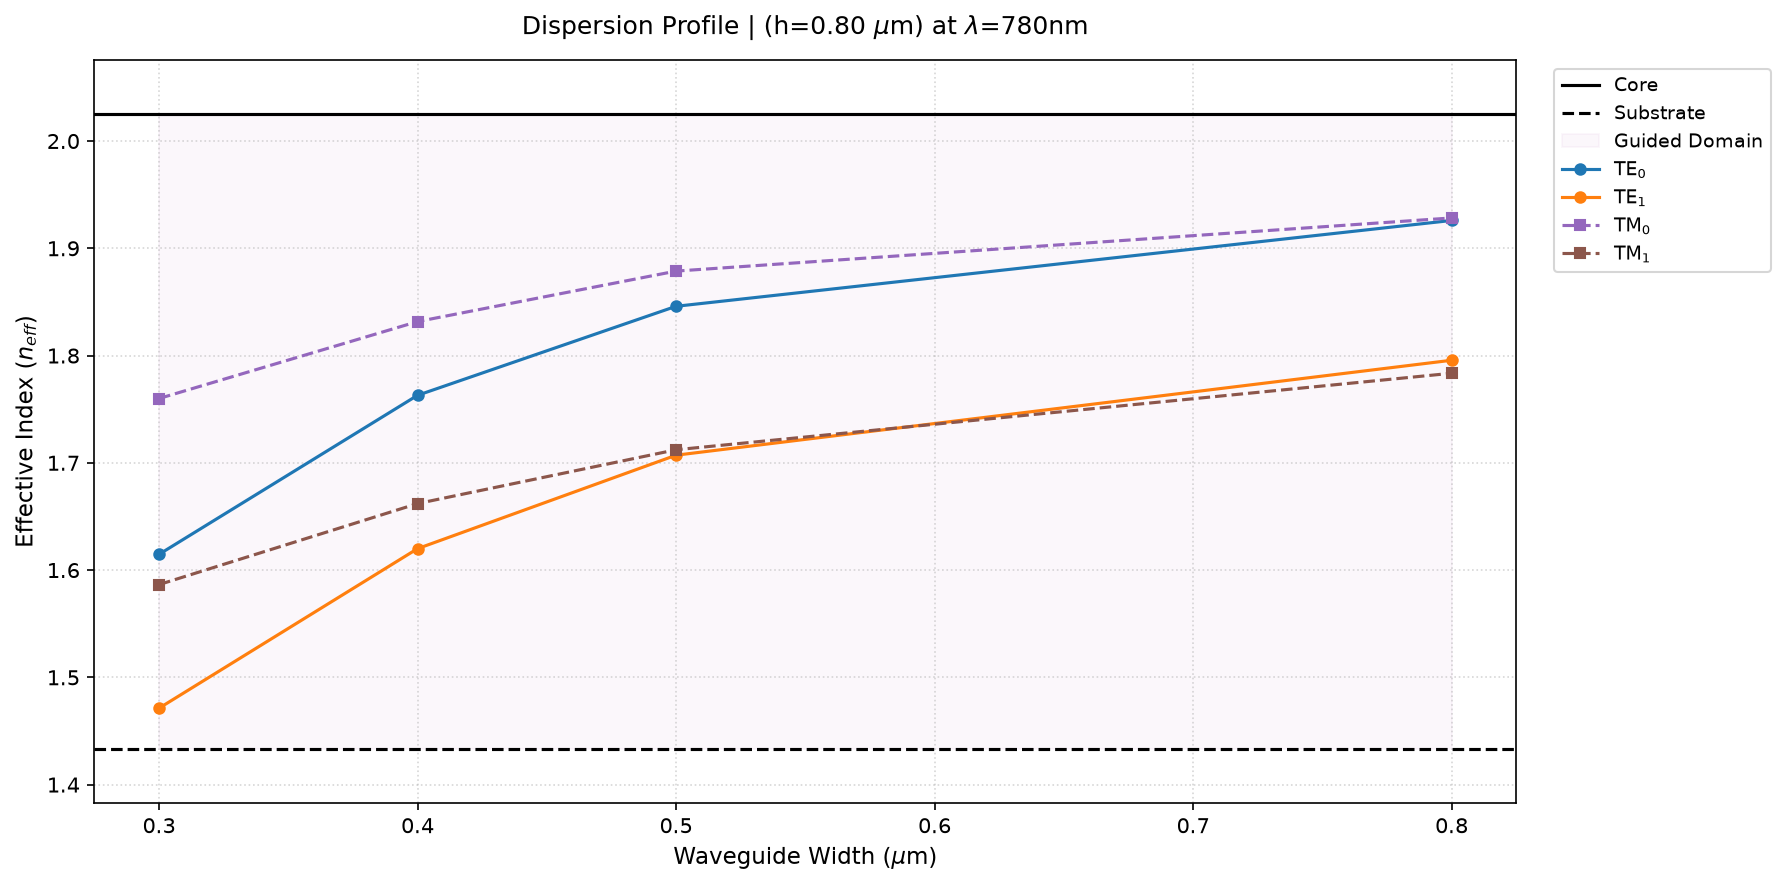

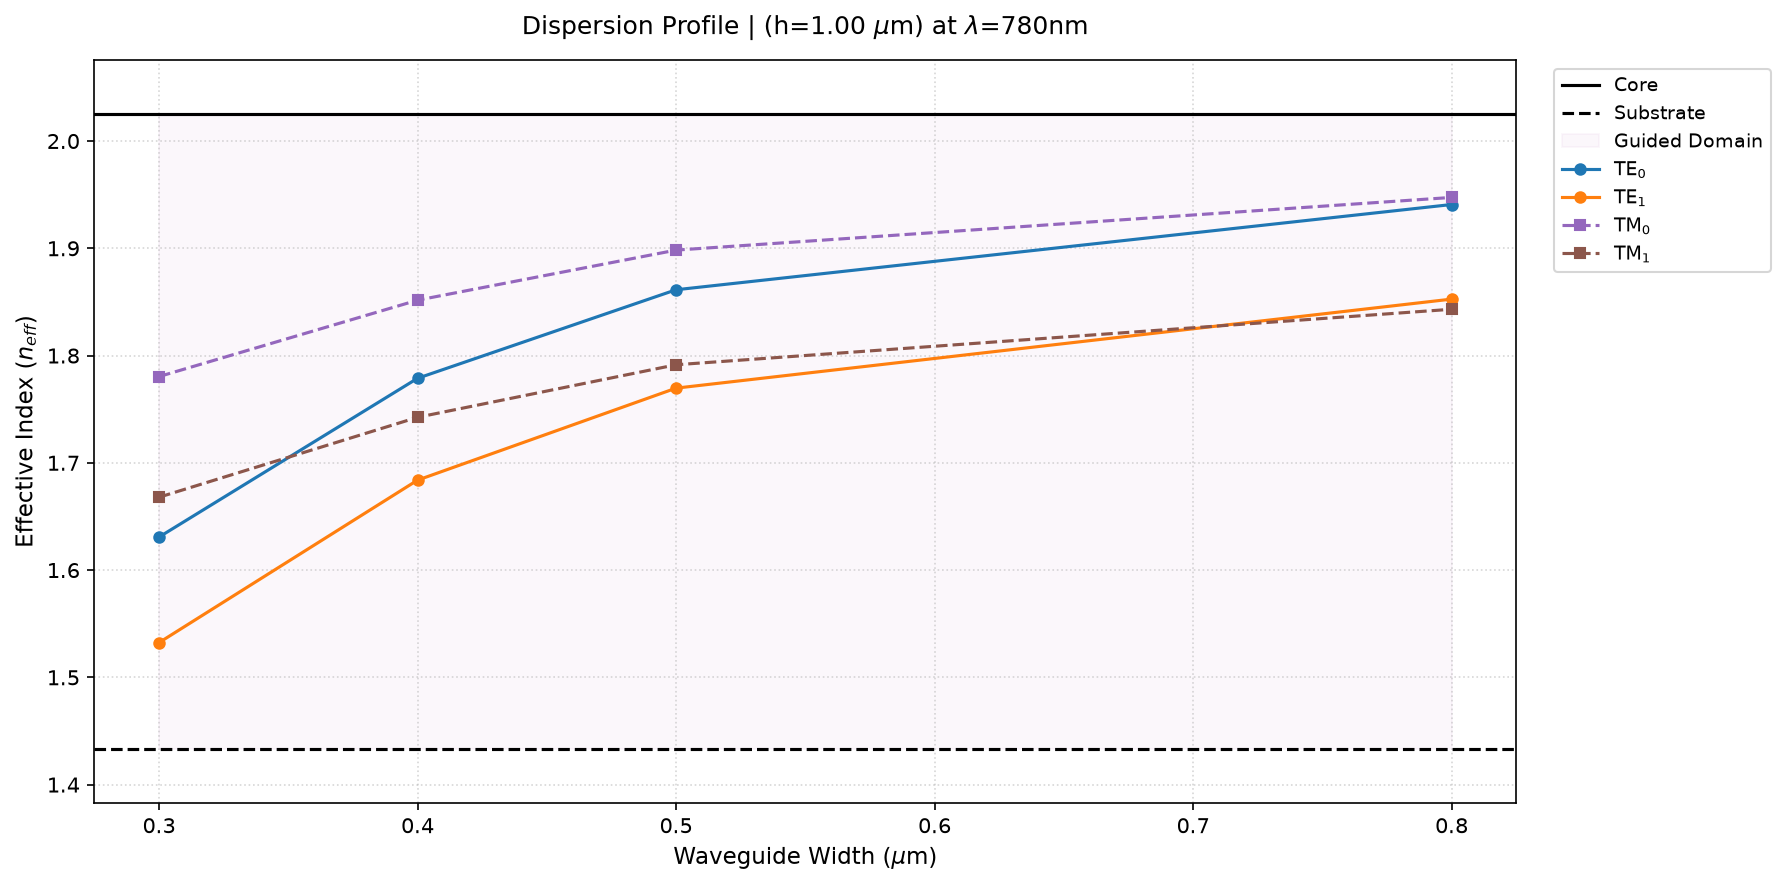

In [ ]:
# ---- Waveguide Mode Analysis and Sweep ---- #

import waveguide
from media import get_medium

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = get_medium("si3n4",(0.600, 1.200))
SiO2 = get_medium("sio2",(0.600, 1.200))

# Call the modes_in_geometry function
waveguide.modes_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    box_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/mode_sweep/",

    wavelength_um   = target_wavelength_um,
    box_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    num_modes       = 4,    # Number of modes computed by the Tidy3D solver

    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

### Confinement Sweep

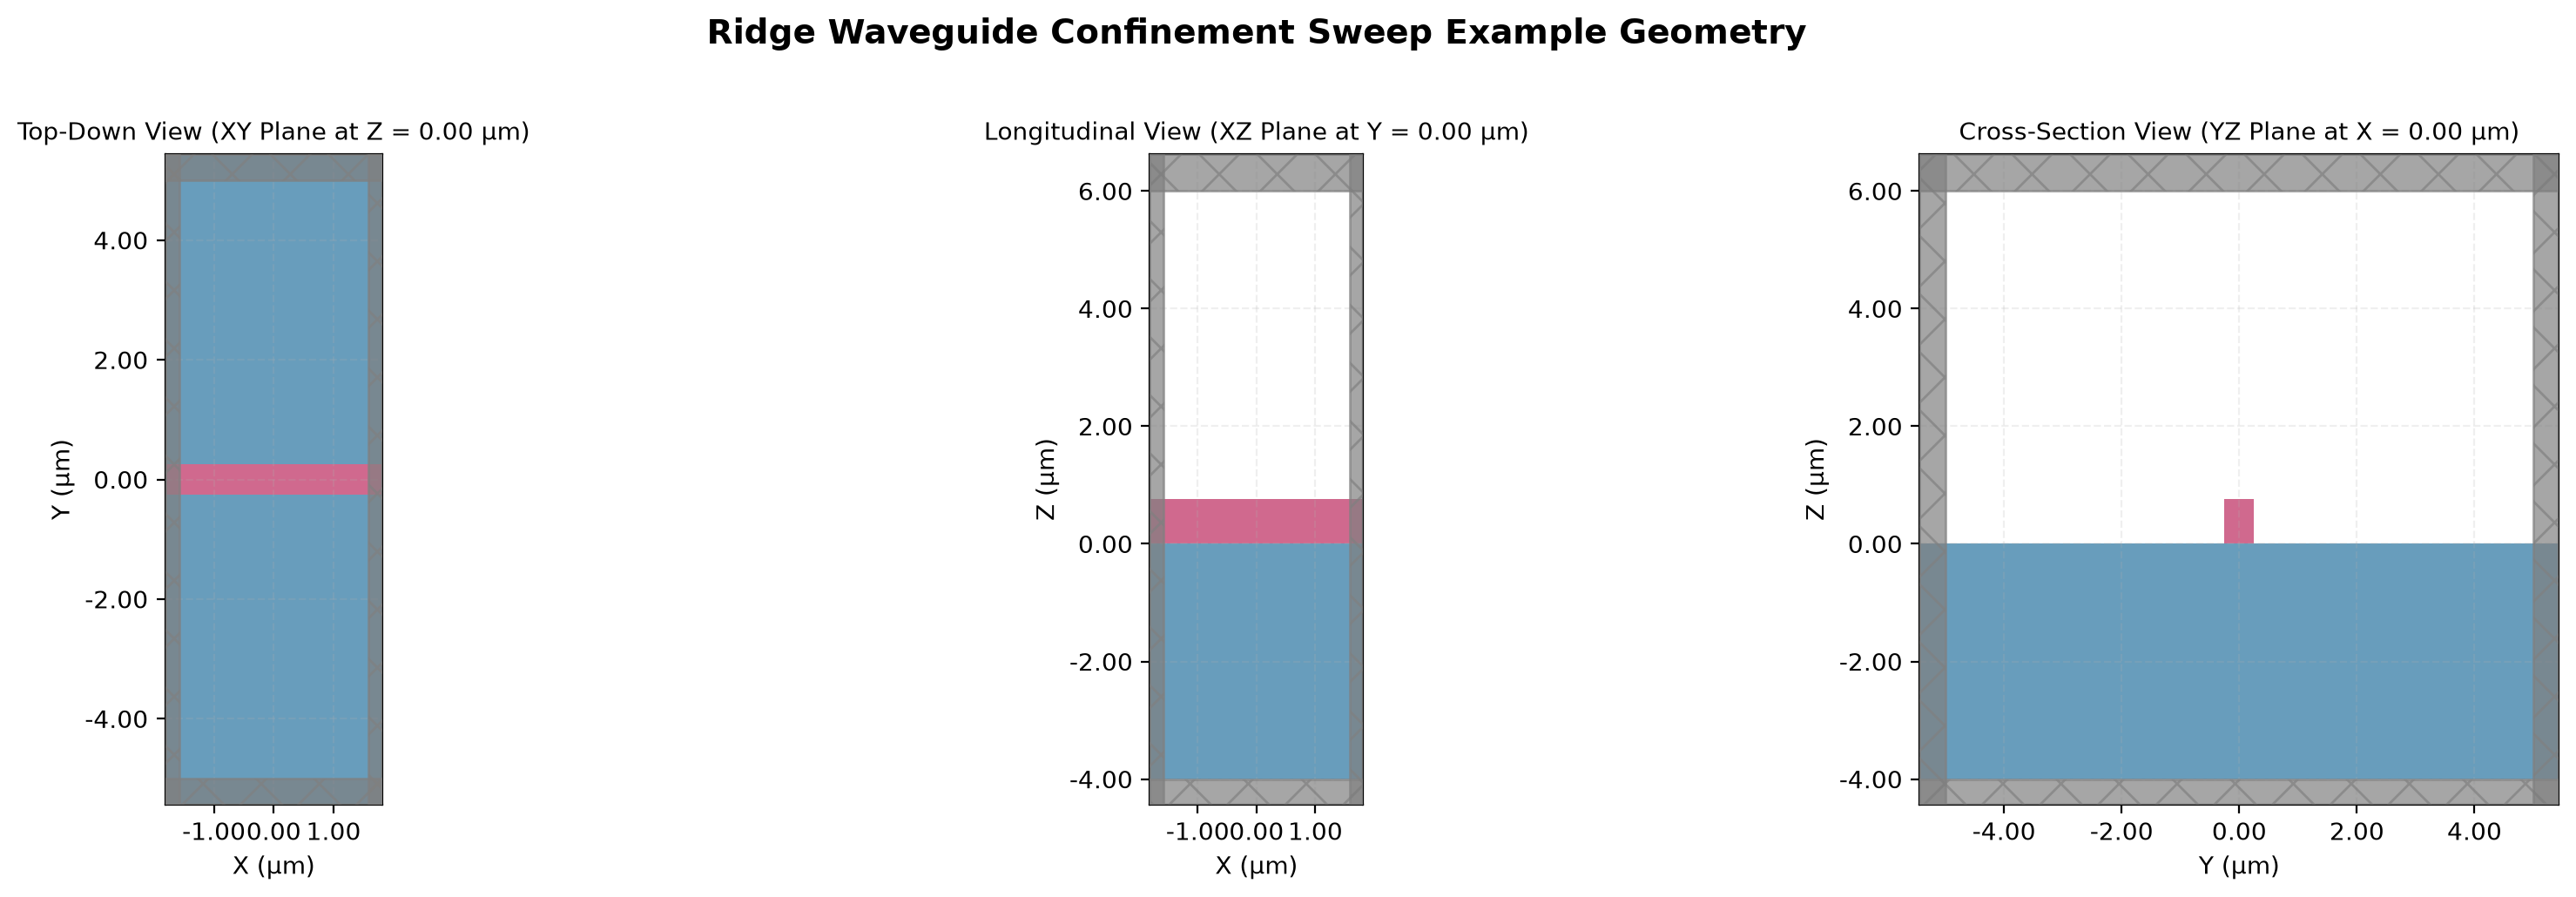

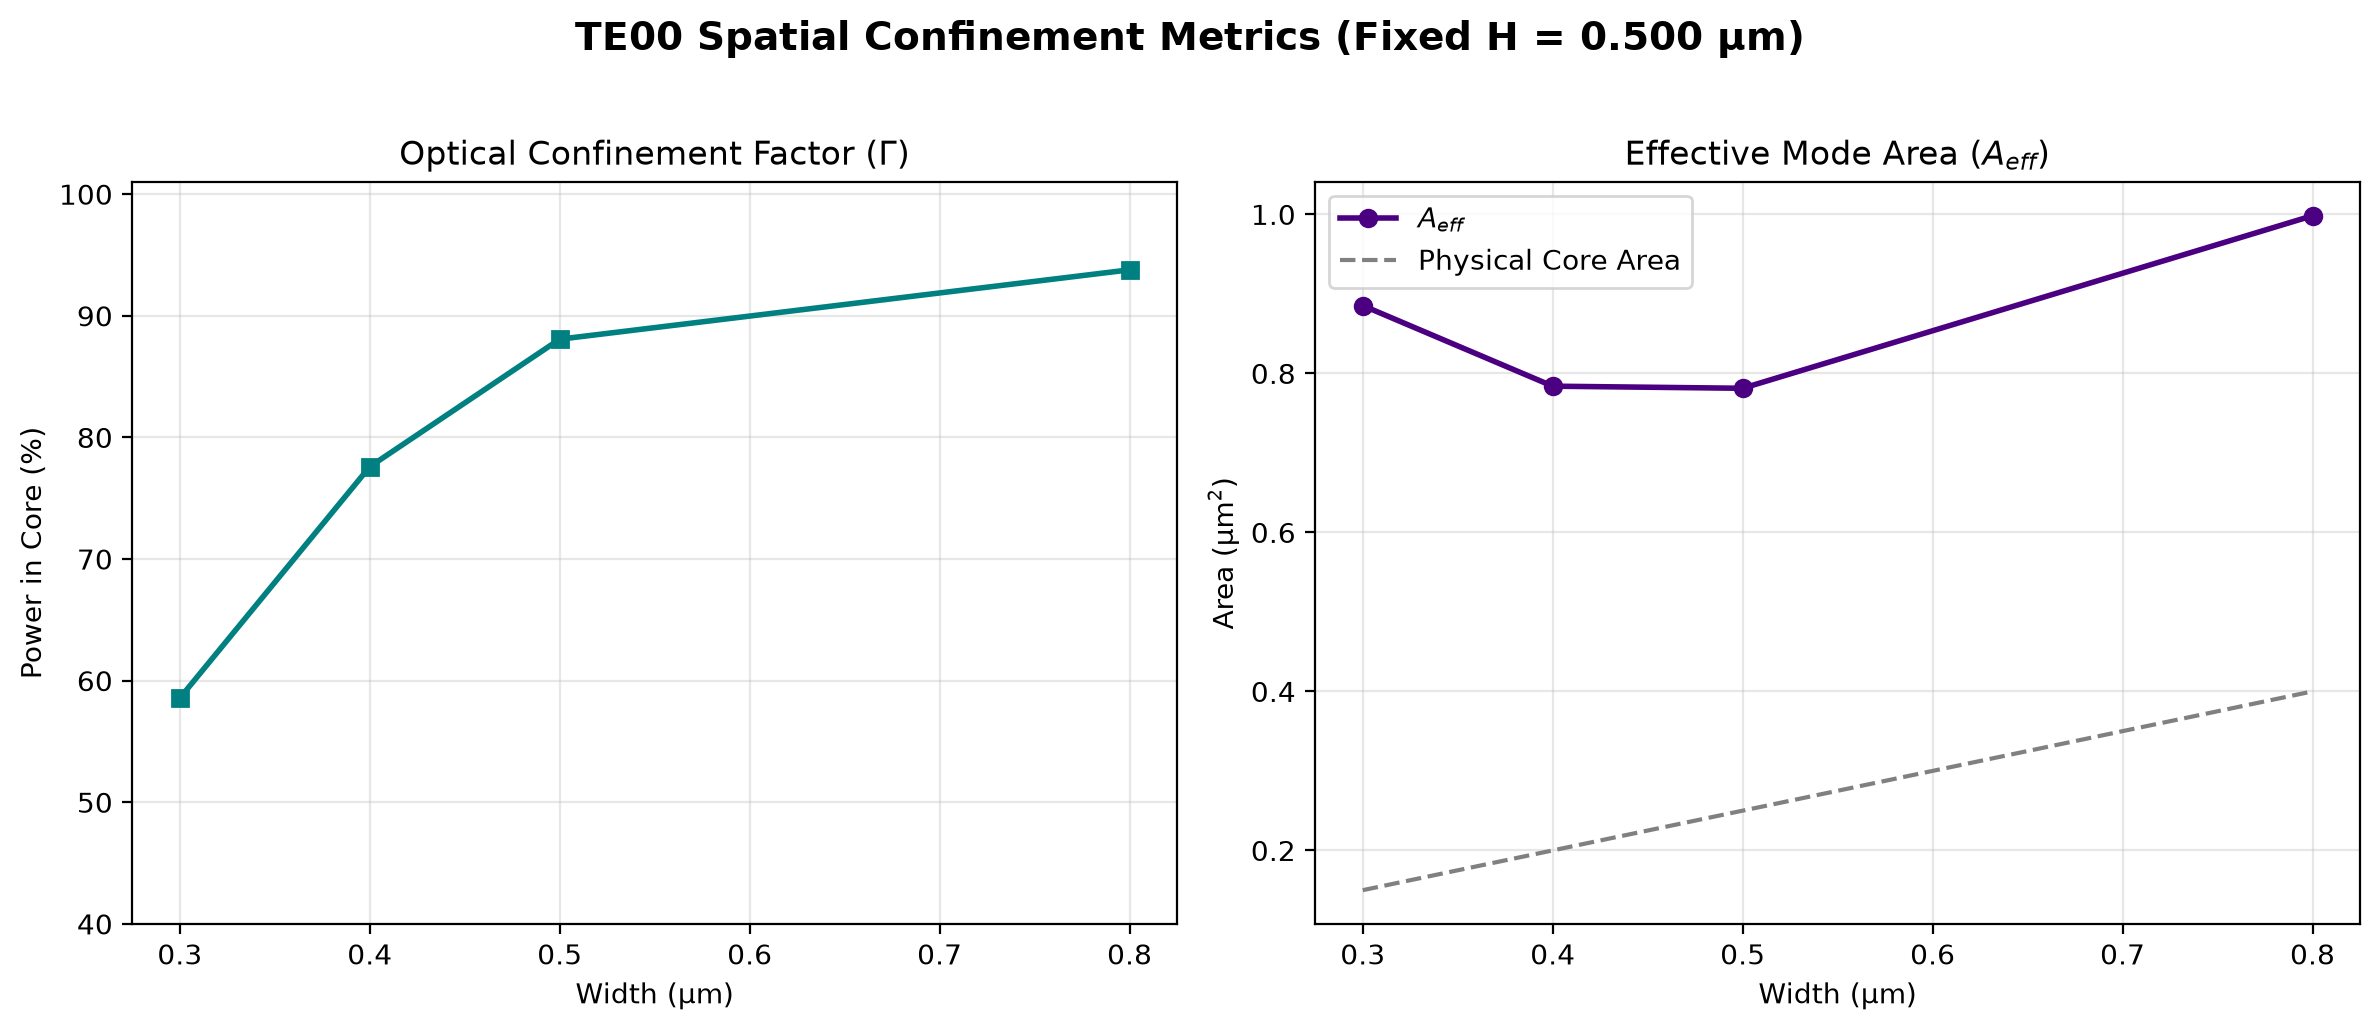

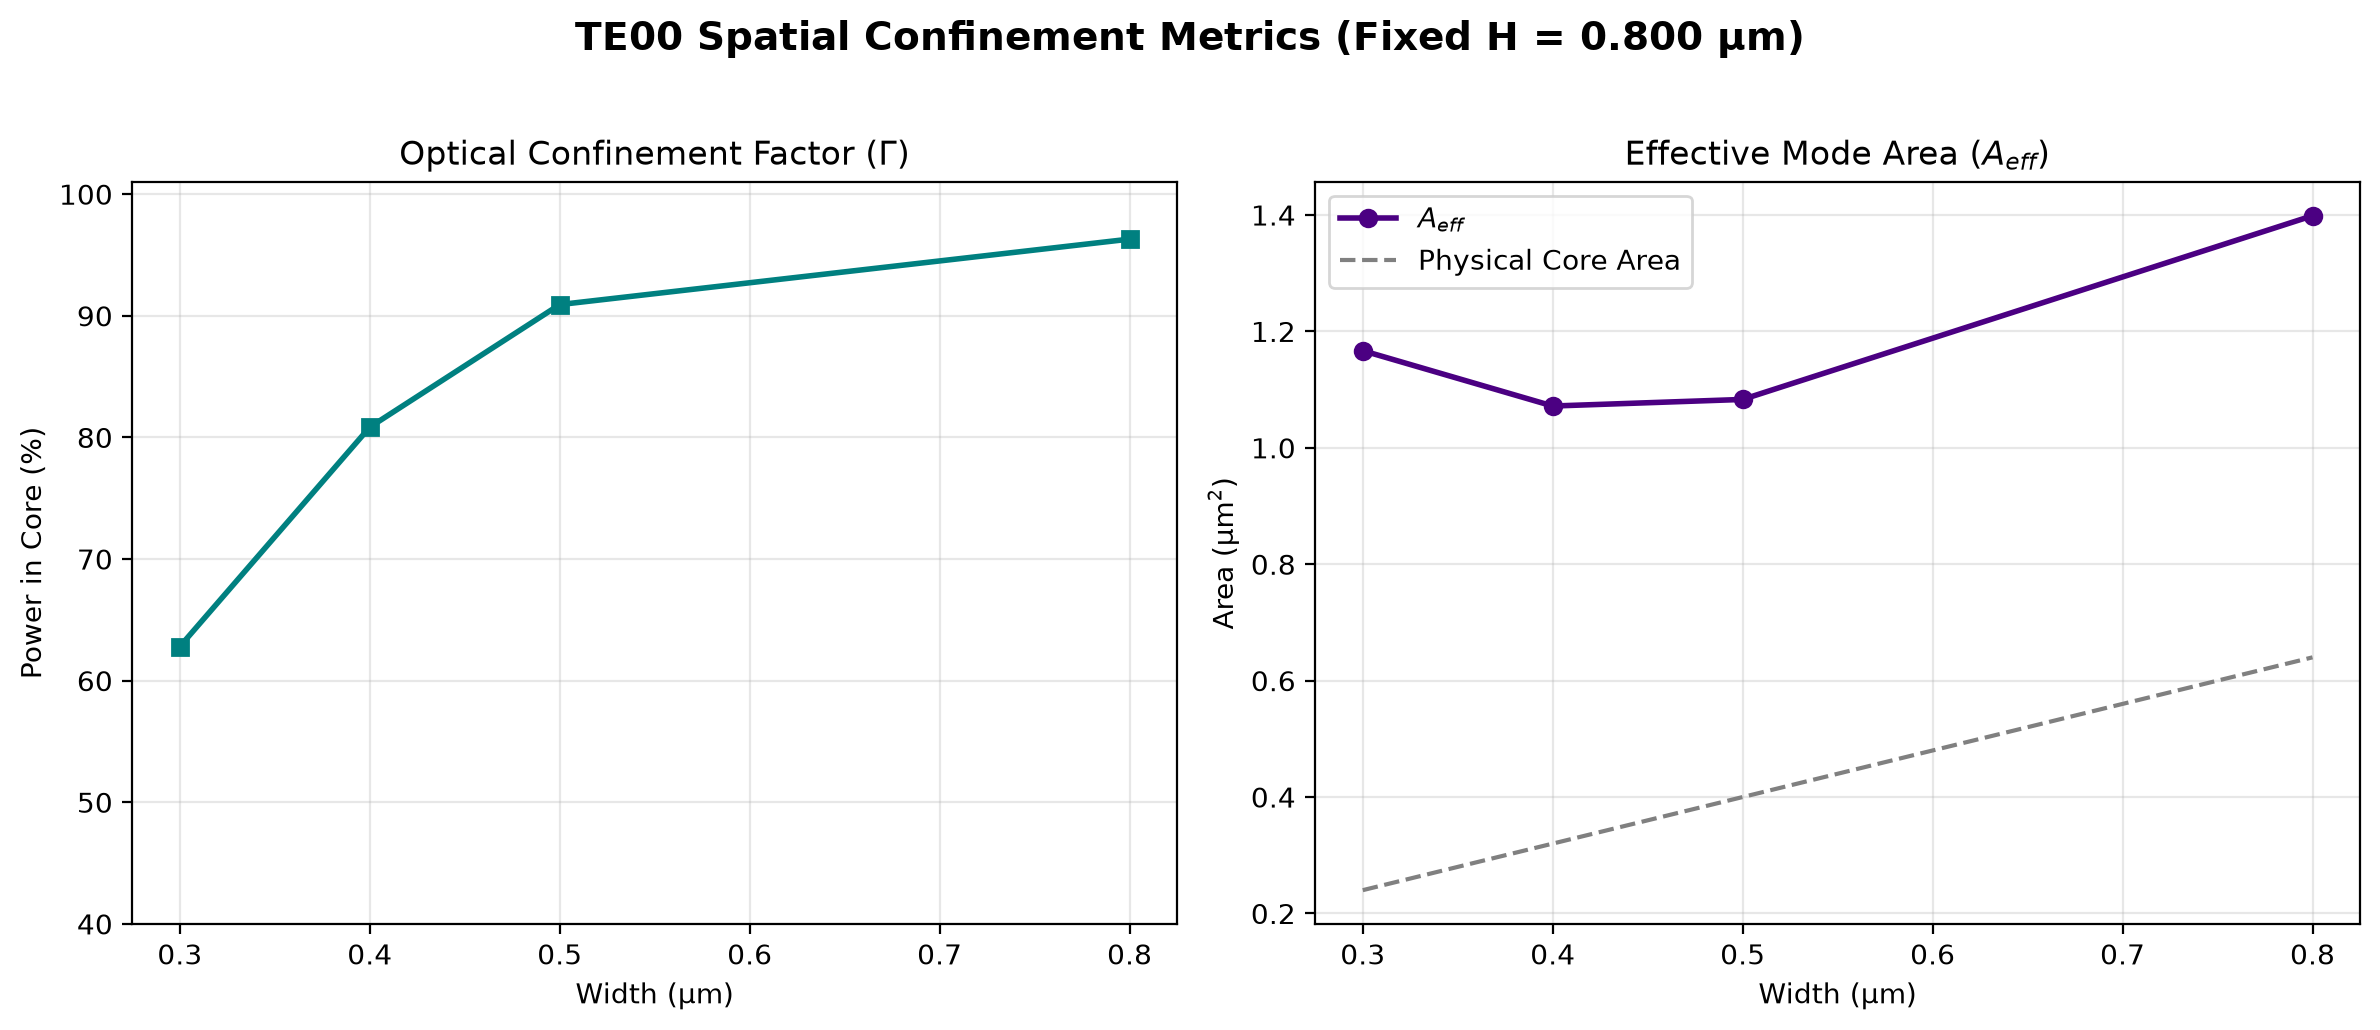

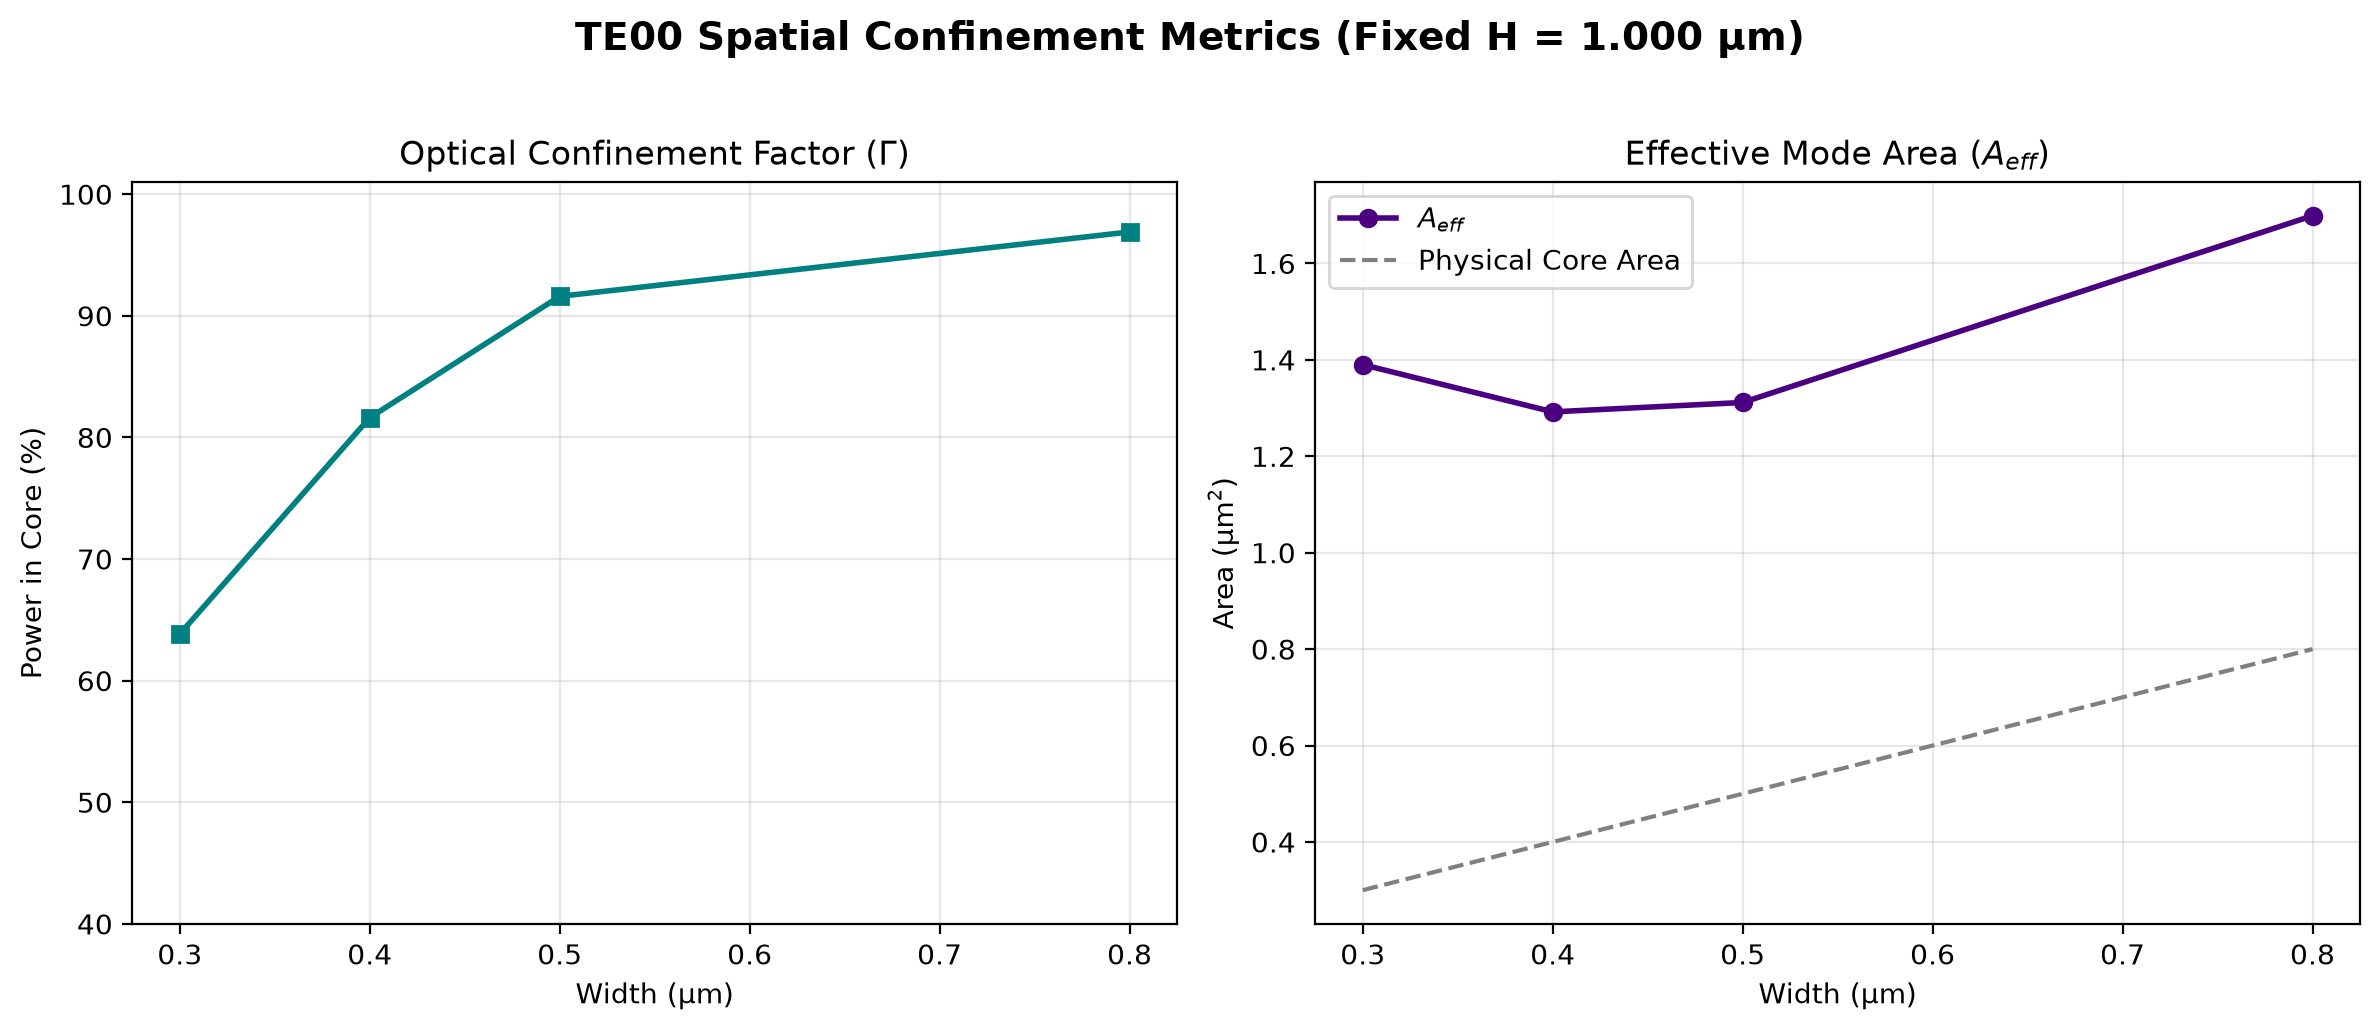

{0.5: ([0.3, 0.4, 0.5, 0.8],
  [58.56807915115498, 77.59070568086284, 88.07591338901847, 93.77803479492941],
  [0.8852380854363316,
   0.783887505219132,
   0.7812454328017384,
   0.9982636114716824]),
 0.8: ([0.3, 0.4, 0.5, 0.8],
  [62.80636795716382, 80.84245256788908, 90.92252778551207, 96.30356064899013],
  [1.16688586205623,
   1.0717827977145806,
   1.0831103929944323,
   1.3987380808826468]),
 1.0: ([0.3, 0.4, 0.5, 0.8],
  [63.84011635683632, 81.62546245166169, 91.59853057565375, 96.893285454787],
  [1.3900354356759734,
   1.2920898911375251,
   1.3115519881759539,
   1.6989125400332825])}

In [8]:
# ---- Waveguide Confinement Analysis and Sweep ---- #

import waveguide
from media import get_medium

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure will have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = get_medium("si3n4",(0.600, 1.200))
SiO2 = get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.confinement_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    box_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/confinement_sweep/",

    wavelength_um   = target_wavelength_um,
    box_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    
    sim_size_y = 10.0,  # Simulation domain size in the y-direction (in microns)
    sim_size_z = 10.0,  # Simulation domain size in the z-direction (in microns)

    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)

### Dispersion Analysis Sweep

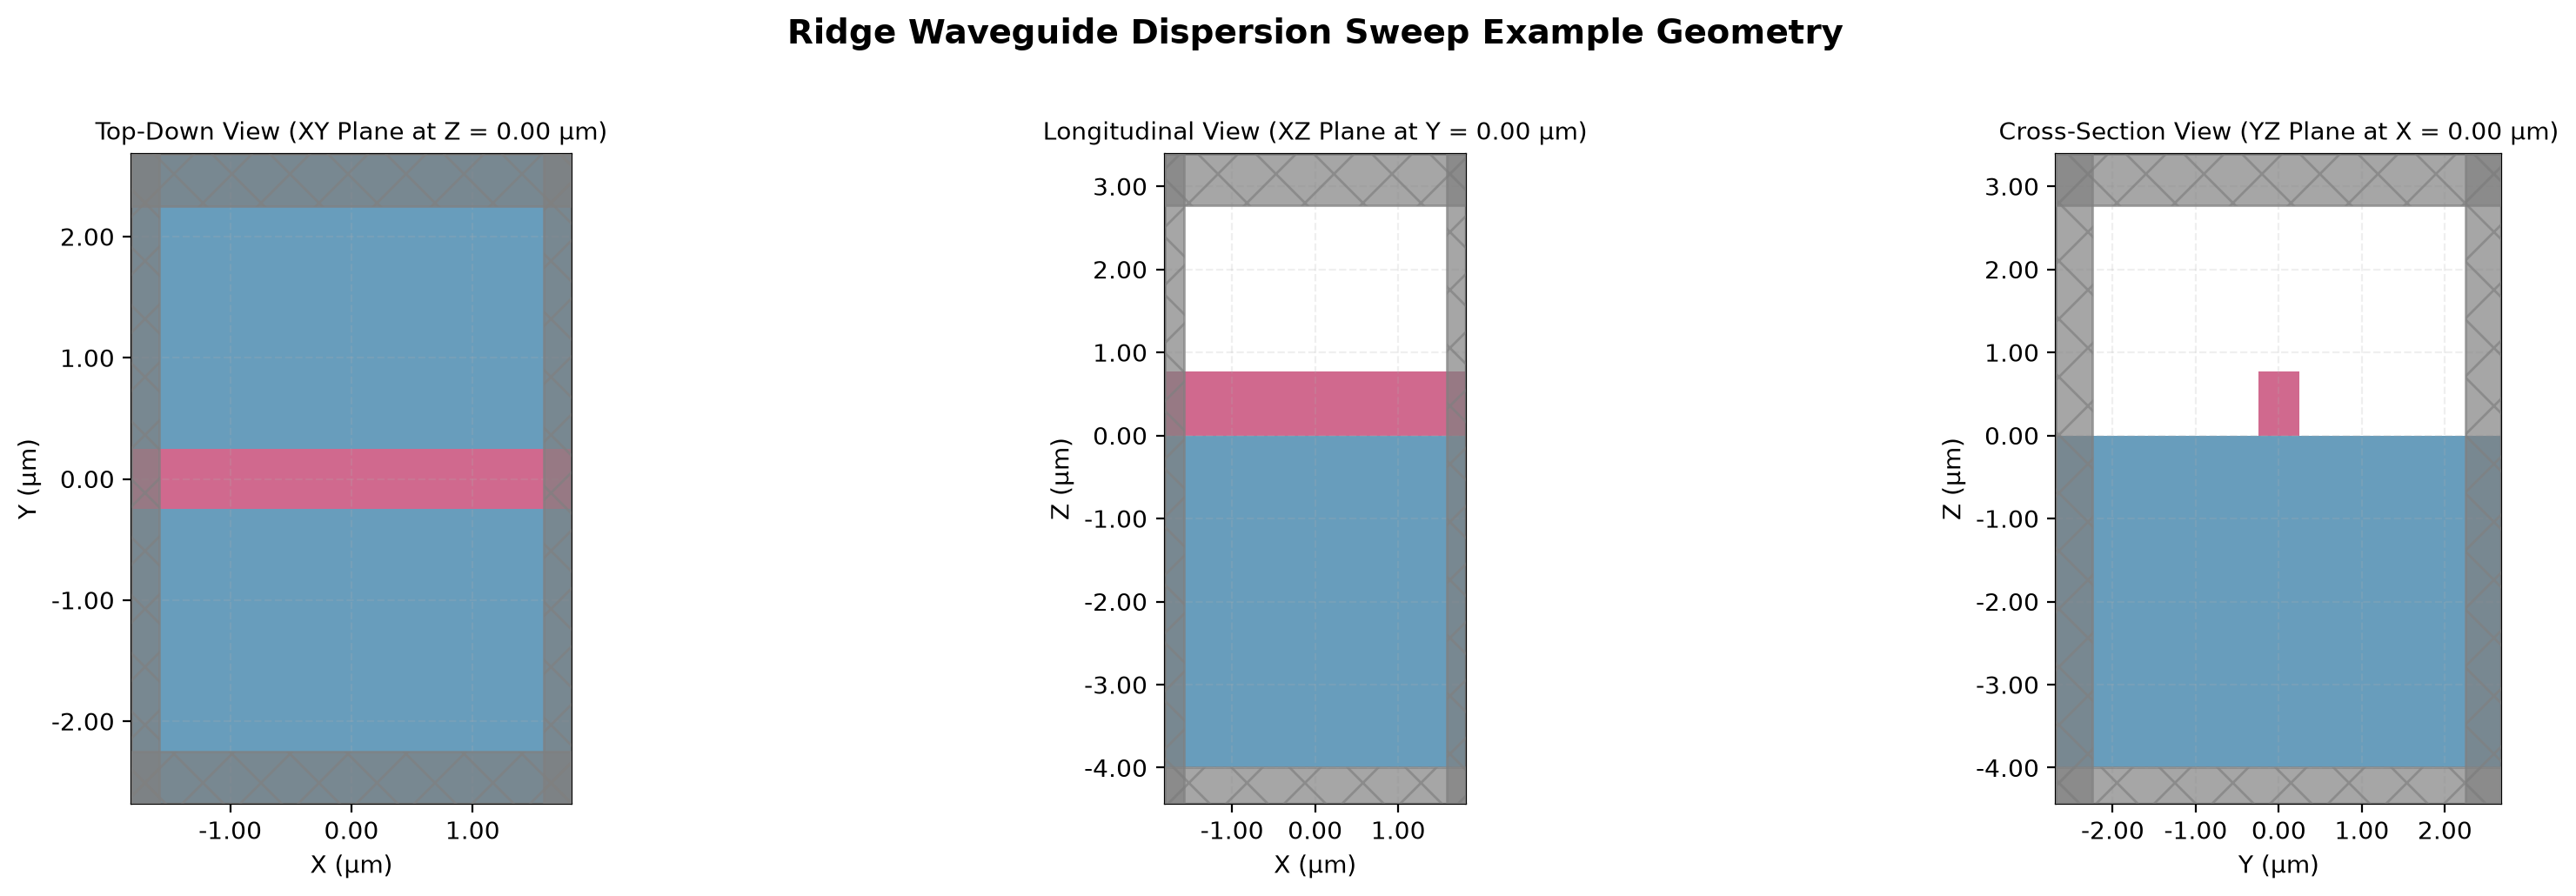

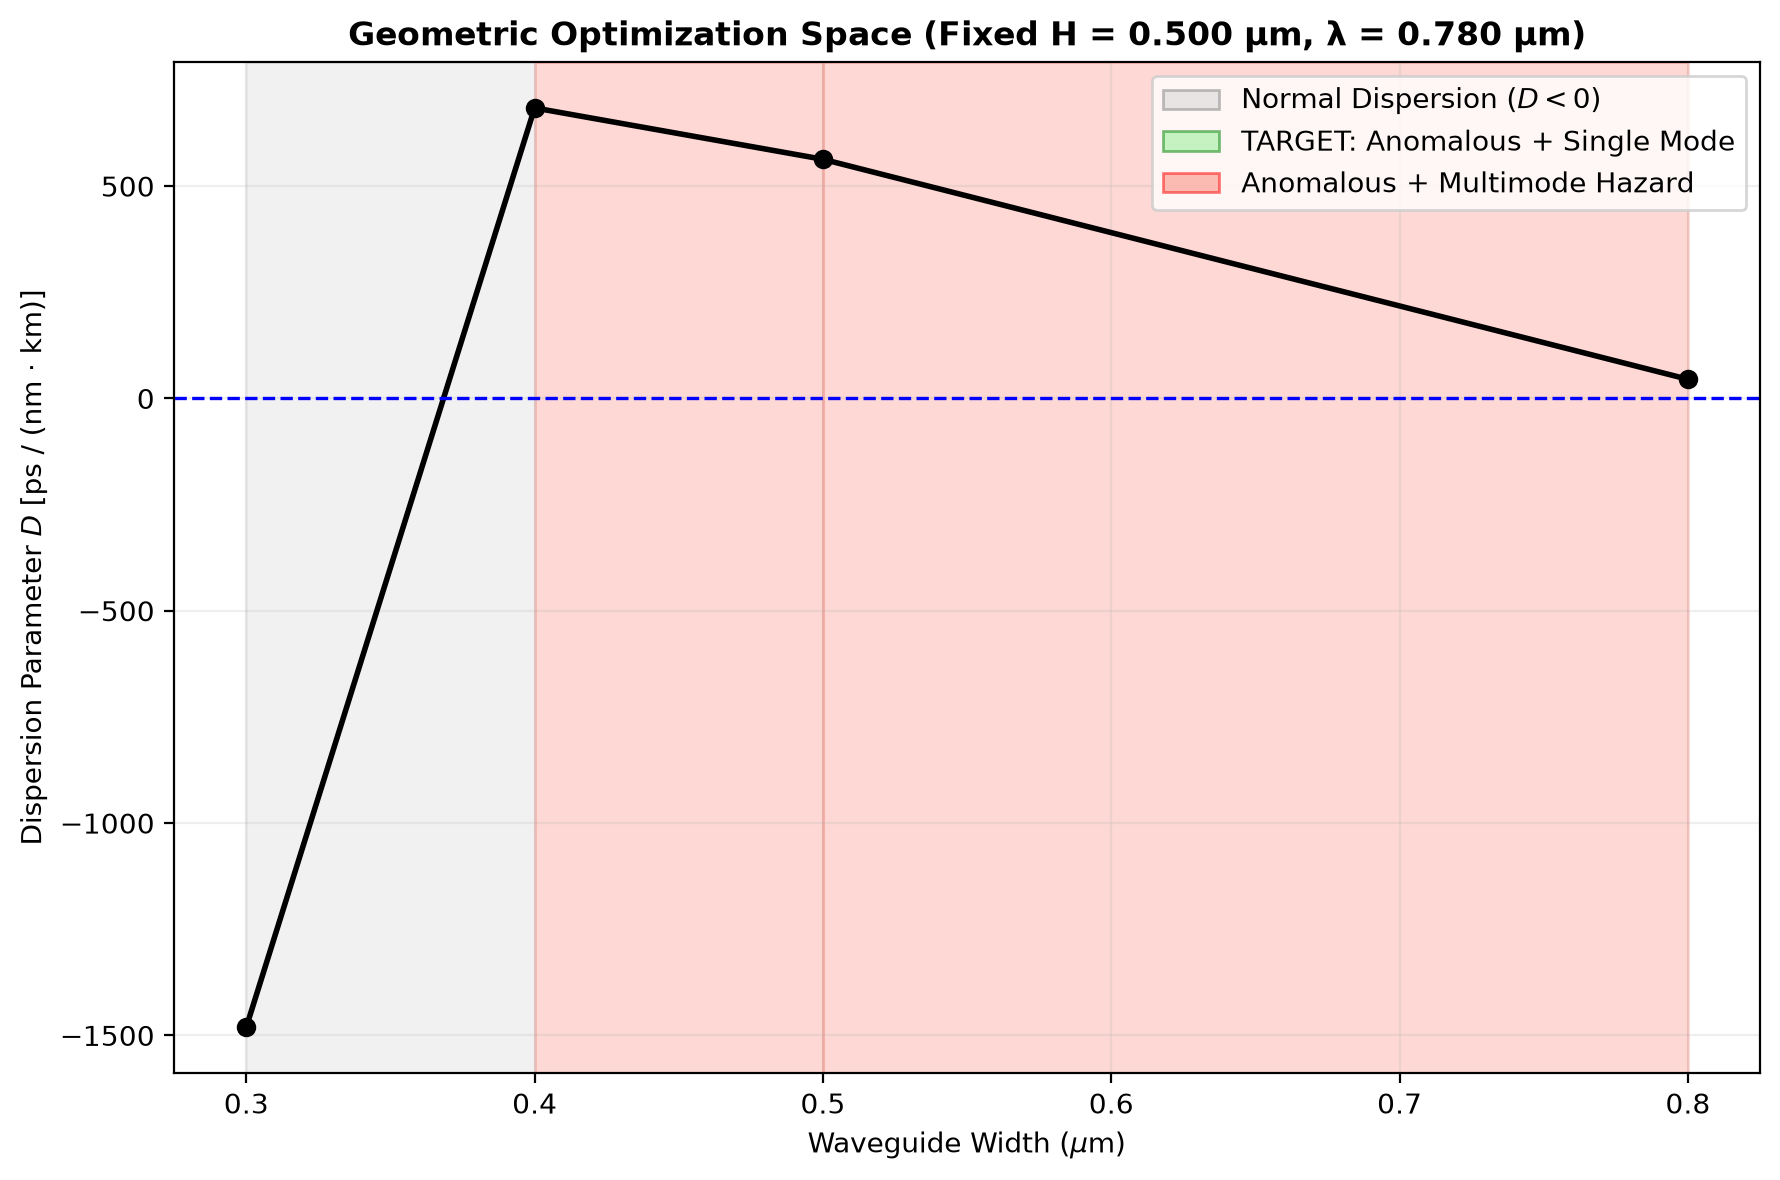

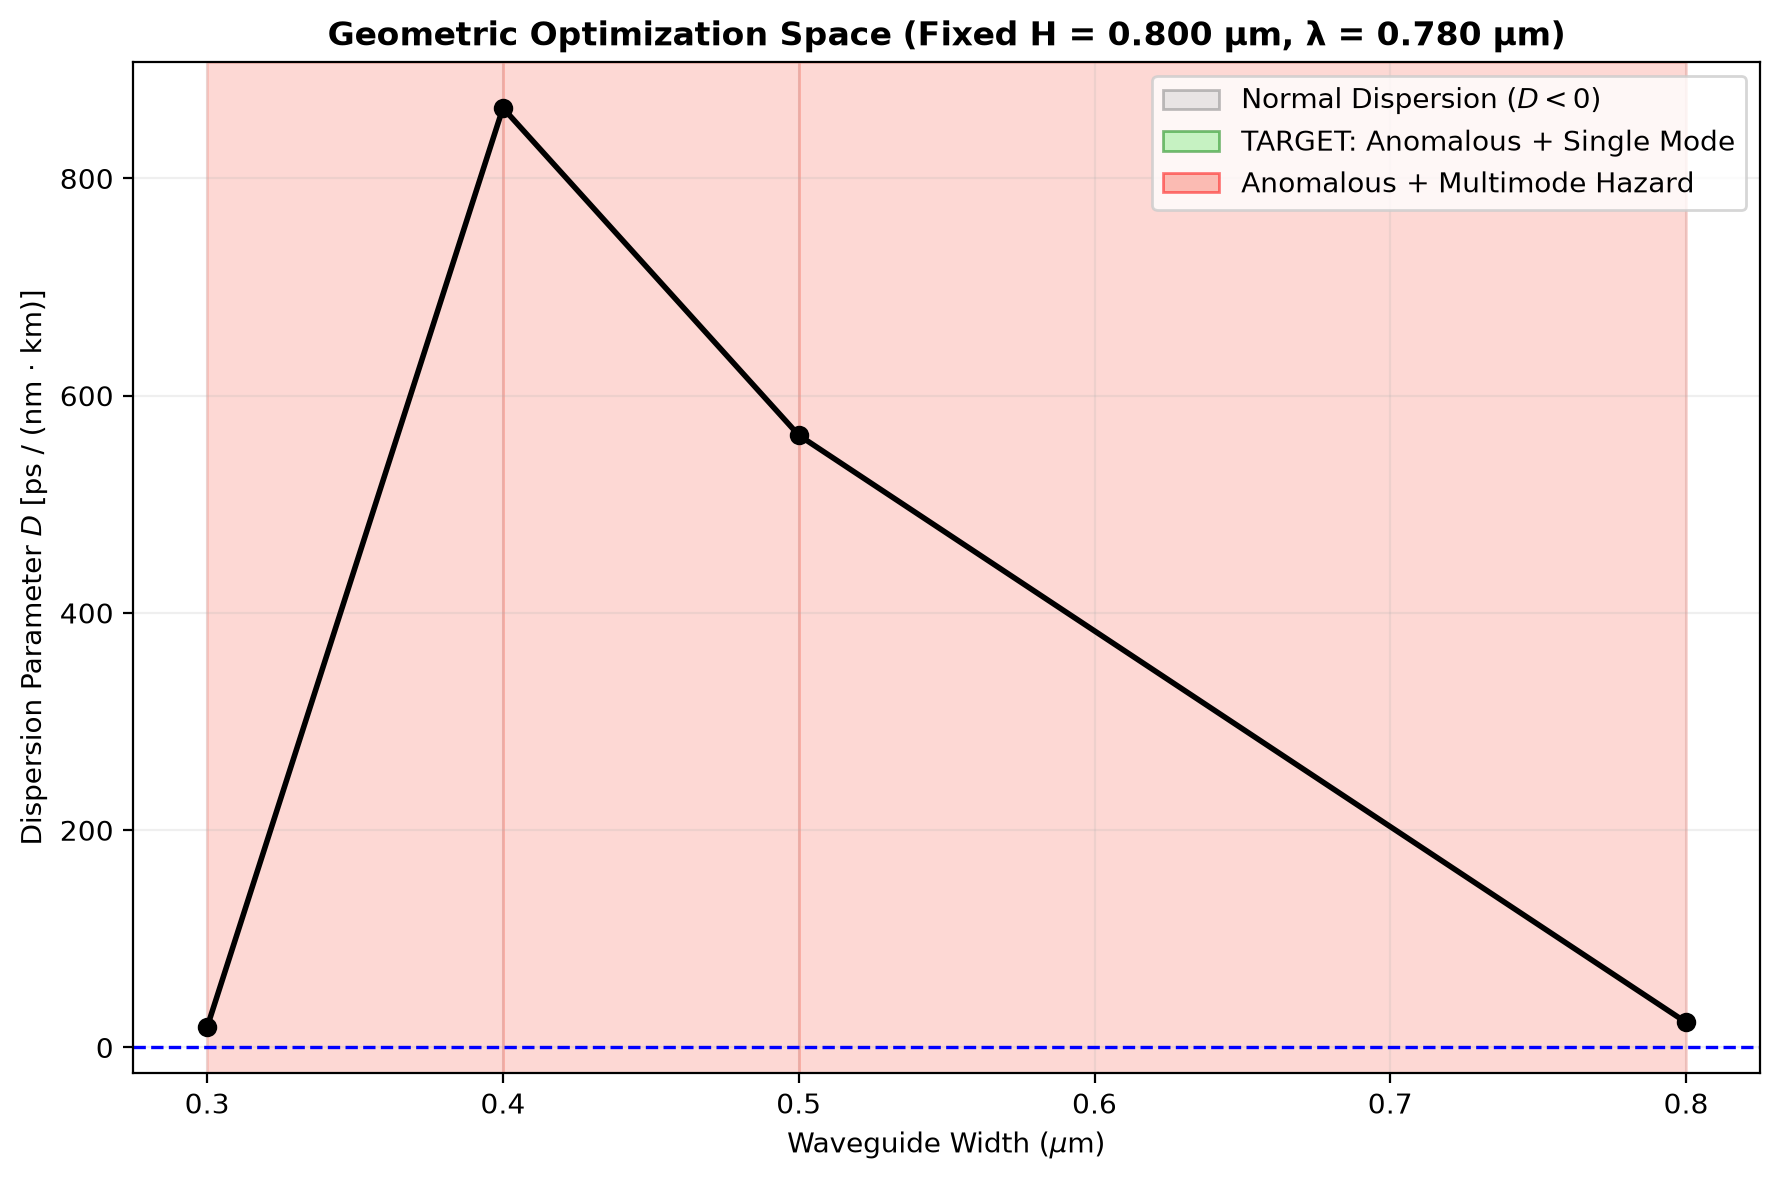

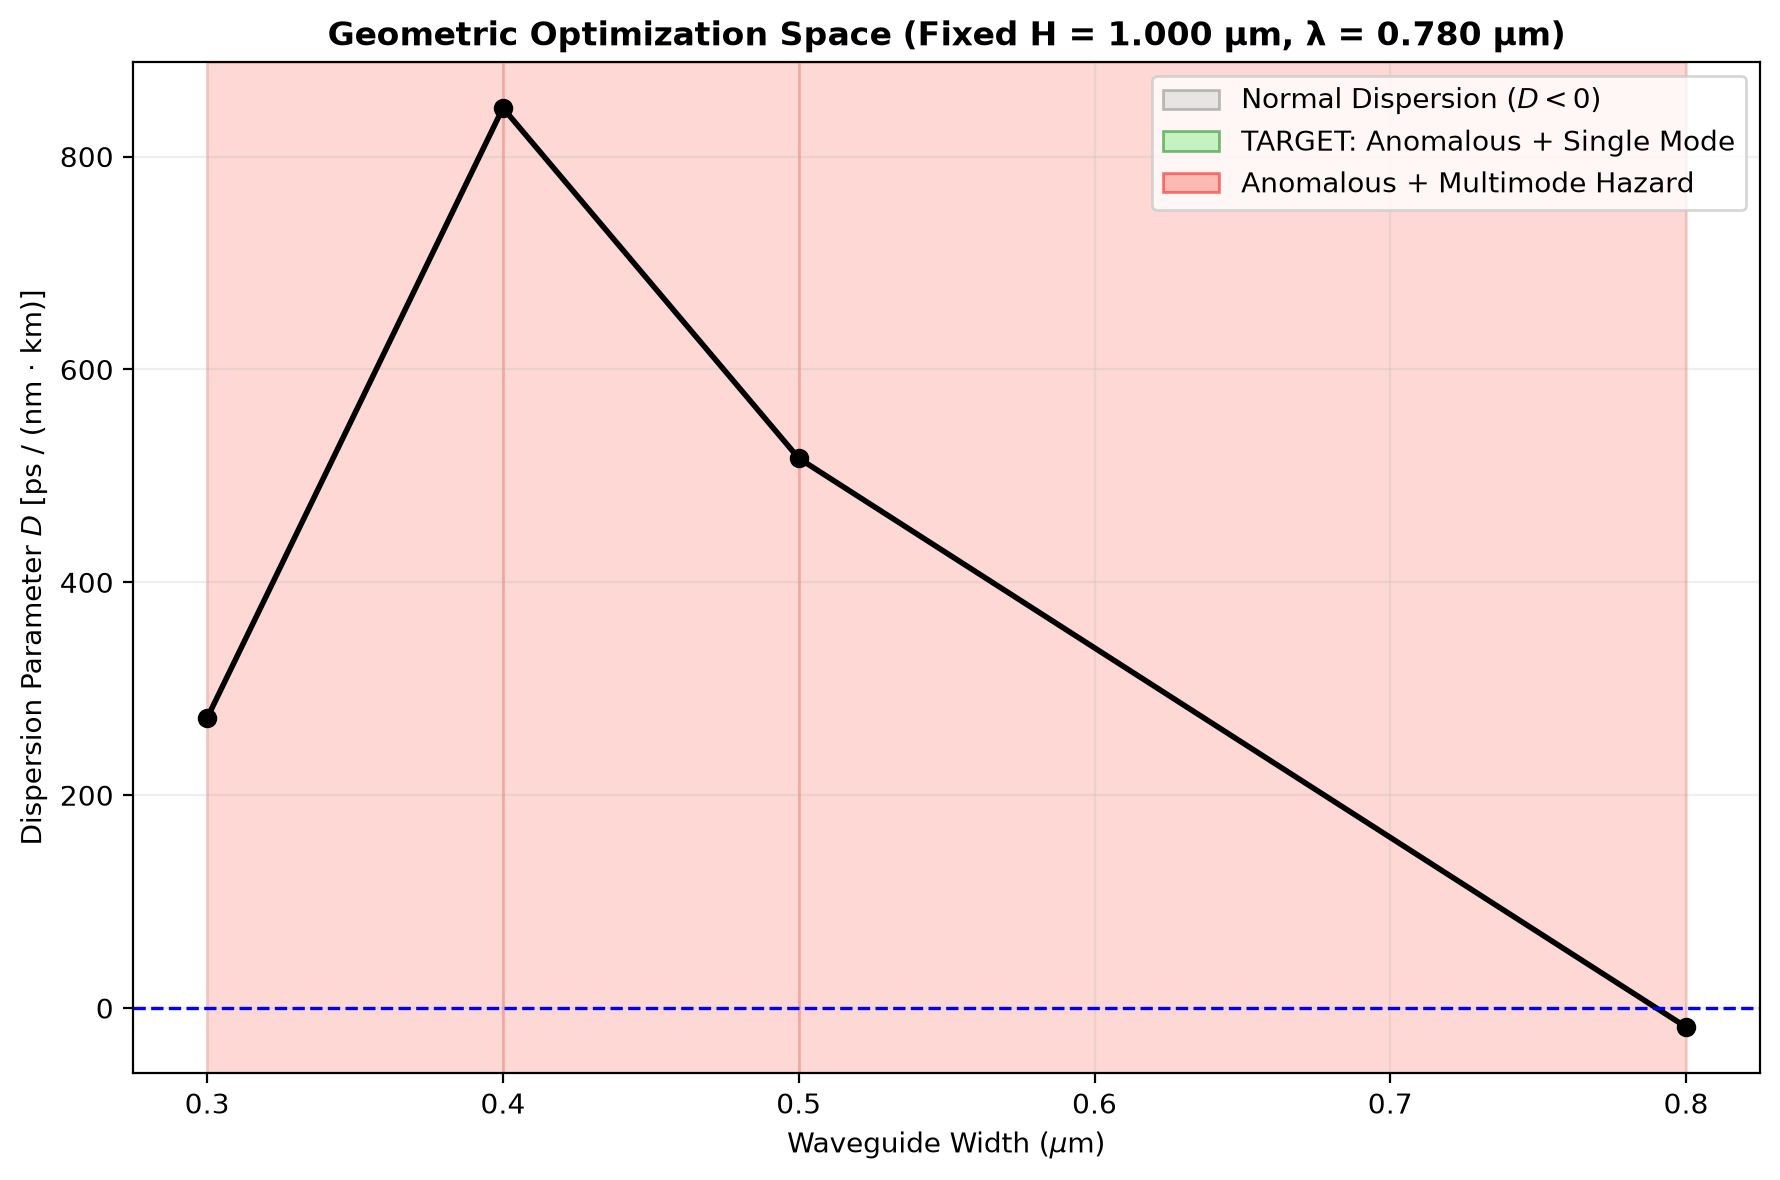

{0.5: ([0.3, 0.4, 0.5, 0.8],
  [-1480.3756848002076,
   684.0417376478152,
   563.1264728920545,
   45.04781746520294],
  [True, False, False, False]),
 0.8: ([0.3, 0.4, 0.5, 0.8],
  [18.78812754075961,
   864.8817786226623,
   563.6312341030496,
   23.083005406651825],
  [False, False, False, False]),
 1.0: ([0.3, 0.4, 0.5, 0.8],
  [272.5642620349664,
   845.6966481420695,
   516.5628076143273,
   -17.84715727260706],
  [False, False, False, False])}

In [9]:
# ---- Waveguide Dispersion Analysis and Sweep ---- #

import waveguide
from media import get_medium

# Define the geometry sweep points
sweep_heights : list = [0.500, 0.800, 1.00] # 3 figures will be generated
sweep_widths : list = [0.300, 0.400, 0.500, 0.800] # Each figure with have 4 data points

# Define the target wavelength at which mode analysis is carried out
target_wavelength_um : float = 0.780

# Get media from the medium helper
SiN = get_medium("si3n4",(0.600, 1.200))
SiO2 = get_medium("sio2",(0.600, 1.200))

# Call the confinement_in_geometry function
waveguide.dispersion_in_geometry(
    sweep_heights   = sweep_heights,
    sweep_widths    = sweep_widths,
    
    core_medium     = SiN,
    box_medium      = SiO2,
    
    # Define the directory in which results are to be stored to
    output_dir_name = "example_results/waveguide/dispersion_sweep/",

    wavelength_um   = target_wavelength_um,
    box_height= 4.0,   # Height of the substrate aka the BOX (in microns)
    
    preview_geometry = True, # Display a preview of the geometry
    display_results = True  # Display the figures (in addition to saving them)
)